In [1]:
import time
import imdlib as imd

for attempt in range(1, 6):                      # try up to 5 times
    try:
        imd.get_data("rain", 2018, 2018, fn_format="yearwise",
                     file_dir="../data/raw/imd")
        print("Downloaded on attempt", attempt)
        break                                    # it worked, so stop the loop
    except Exception as e:                       # it failed, so don't crash
        print(f"Attempt {attempt} failed: {type(e).__name__}")
        time.sleep(10)                           # wait 10 seconds, then retry

File already exists: ../data/raw/imd/rain/2018.grd. Skipping download.
Download Successful !!!
Downloaded on attempt 1


In [3]:
import os
import numpy as np
f = "../data/raw/imd/rain/2018.grd"
print(os.path.getsize(f), "bytes")
raw = np.fromfile(f, dtype="<f4")      # the file read as plain 32-bit numbers
print(raw.size, "numbers")
print(raw.min(), raw.max())
print((raw == -999).mean(), "share of -999")

25425900 bytes
6356475 numbers
-999.0 534.24585
0.7149583692219351 share of -999


Matplotlib is building the font cache; this may take a moment.


Text(0.5, 1.0, '16 Aug 2018')

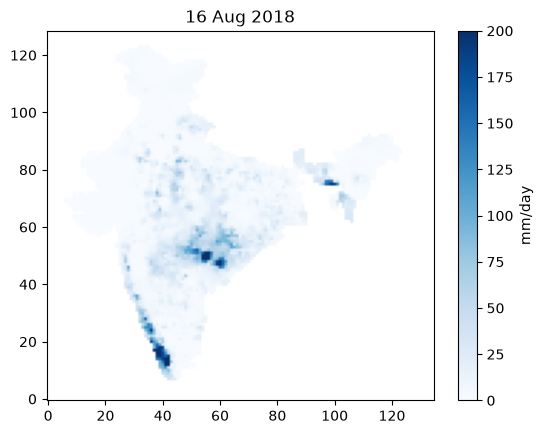

In [4]:
import matplotlib.pyplot as plt
grid = raw.reshape(365, 129, 135)          # (day, lat, lon)
day = np.where(grid[227] == -999, np.nan, grid[227])
plt.imshow(day, origin="lower", cmap="Blues", vmax=200)
plt.colorbar(label="mm/day"); plt.title("16 Aug 2018")

<xarray.Dataset> Size: 51MB
Dimensions:  (time: 365, lat: 129, lon: 135)
Coordinates:
  * time     (time) datetime64[ns] 3kB 2018-01-01 2018-01-02 ... 2018-12-31
  * lat      (lat) float64 1kB 6.5 6.75 7.0 7.25 7.5 ... 37.75 38.0 38.25 38.5
  * lon      (lon) float64 1kB 66.5 66.75 67.0 67.25 ... 99.25 99.5 99.75 100.0
Data variables:
    rain     (time, lat, lon) float64 51MB ...
Attributes:
    Conventions:  CF-1.7
    title:        IMD gridded data
    source:       https://imdpune.gov.in/
    history:      2026-11-19 06:19:42.891782 Python
    references:   
    comment:      
    crs:          epsg:4326


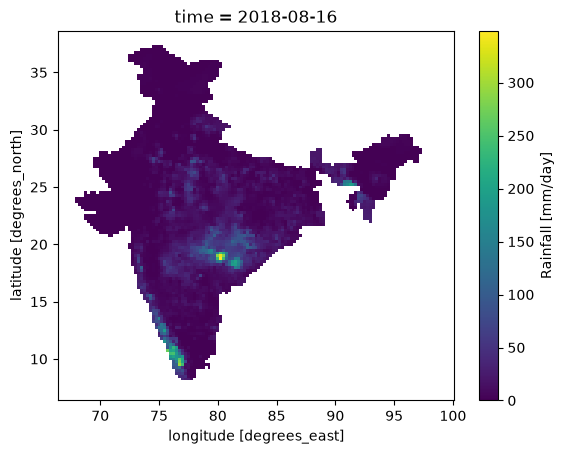

In [5]:
import xarray as xr
ds = xr.open_dataset("../data/raw/imd/rain/rain_2018.nc")
print(ds)                                   # the labels stored inside the file
ds.rain.sel(time="2018-08-16").plot()